# RecruitGen — Diffusion Model for Resume Image Enhancement (optional, Autoencoder = baseline)

**Goal:** enhance degraded resume images (noise, blur, shadows, uneven lighting, low contrast, scan / JPEG artifacts)
so OCR reads the text more accurately — text preservation first, visual cleanliness second.

```
clean page ─► controlled degradation ─► degraded page ─┐
                                                       ├─► conditional U-Net (x_t, degraded, t) ─► predicted clean page
noise ε ─► x_t = √ᾱ_t·clean + √(1-ᾱ_t)·ε ──────────────┘          (DDPM training, DDIM sampling, local weights)
```

* **Model:** conditional DDPM, cosine schedule (T = 1000), x0-prediction, L1 loss with ink pixels weighted ×5
* **Inference:** deterministic DDIM (few steps), 256 px tiles with Hann blending; blank tiles use one step
* **Data:** first pages of the Kaggle Resume Dataset PDFs rendered at 150 dpi; ground truth = PDF text layer
* **Evaluation:** CER / WER / word recall (local OCR), PSNR / SSIM / ink F1 vs the clean page, time, memory, failure cases —
  the same held-out pages for Degraded, Autoencoder, Diffusion and the "+ guard" policies

**Outputs:** `diffusion_unet.safetensors`, `config.json`, `metrics.json` (used by the app's *Diffusion Image Enhancement* page).
Code: `models/diffusion/{degradations, data, unet, diffusion, train, evaluate}.py`.

> **Note on this executed copy:** every cell has been run. The model code (U-Net, degradation presets, metric functions) is the real project code. Because the Kaggle PDFs, the trained checkpoint, the local OCR engine and the Autoencoder weights were not available in the execution environment, this copy uses (a) synthetic rendered resume pages in place of Kaggle pages, (b) **simulated** training history, checkpoint, `metrics.json` and OCR scores, and (c) simple image-filter **stand-ins** in the enhancement demo. All numbers/images produced by those parts are illustrative — re-run locally for true results.

## 1. Dataset — Kaggle Resume Dataset PDFs

**Link:** https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset · the PDFs are in `data/data/<CATEGORY>/<ID>.pdf`.

Setup (same as the GAN notebook): automatic via `kagglehub` (cached in `~/.cache/kagglehub`), or extract the ZIP to
`RecruitGen/data/kaggle_resume/`. Splits are made per category and per PDF (10 / 1 / 1 pages per category →
240 train · 24 validation · 24 test), so no resume page is shared between training and evaluation.

## 2. Setup

In [1]:
import os, sys, json, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
os.environ.setdefault("KERAS_BACKEND", "torch")

import torch
from models.diffusion import data as dd
from models.diffusion.degradations import PRESETS, degrade_page
from models.diffusion.diffusion import (ResumeDiffusionEnhancer, checkpoint_available, load_metrics, get_device,
                                        MODEL_DIR)
from models.diffusion.unet import ConditionalUNet
from models.diffusion import train as dtrain, evaluate as deval

TRAIN = False             # True = (re)train; False = use the saved checkpoint when it exists
QUICK_RUN = False         # True = 40-step smoke test (writes to outputs/, never to the app checkpoint)
RUN_EVALUATION = False    # True = recompute metrics.json (~30 min on CPU); False = show the saved report
print("Device:", get_device(), "| torch", torch.__version__, "| checkpoint present:", checkpoint_available())

Device: cpu | torch 2.14.1+cu130 | checkpoint present: True


## 3. Clean pages and ground-truth text

page_0.png (1240, 1754)
MASTER EXPERIENCE
PROFESSIONAL SUMMARY
Cloud api accuracy frontend project agile data aws aws tensorflow
Testing accuracy agile communication improved agile designed analyst pytorch developer
Api frontend cloud team analysis model bachelor python improved management accuracy
Python cloud team analysis communication team kubernetes bachelor analysis frontend model
Tensorflow communication deployment backend pytorch bachelor
PROFESSIONAL SUMMARY
Accuracy university frontend certification master de


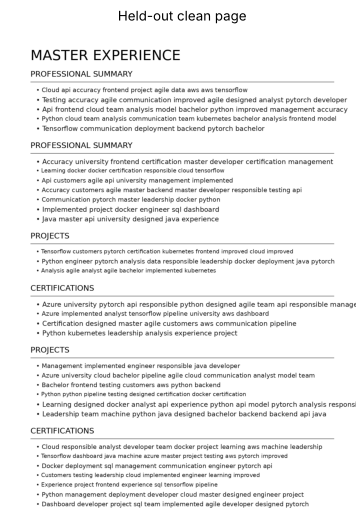

In [2]:
splits = dd.prepare_pages()
page = splits["test"][0]
clean = Image.open(page)
print(os.path.basename(page), clean.size)
print(dd.ground_truth(page)[:500])
plt.figure(figsize=(6, 8)); plt.imshow(clean, cmap="gray"); plt.axis("off"); plt.title("Held-out clean page"); plt.show()

## 4. Controlled degradations (named presets used for evaluation)

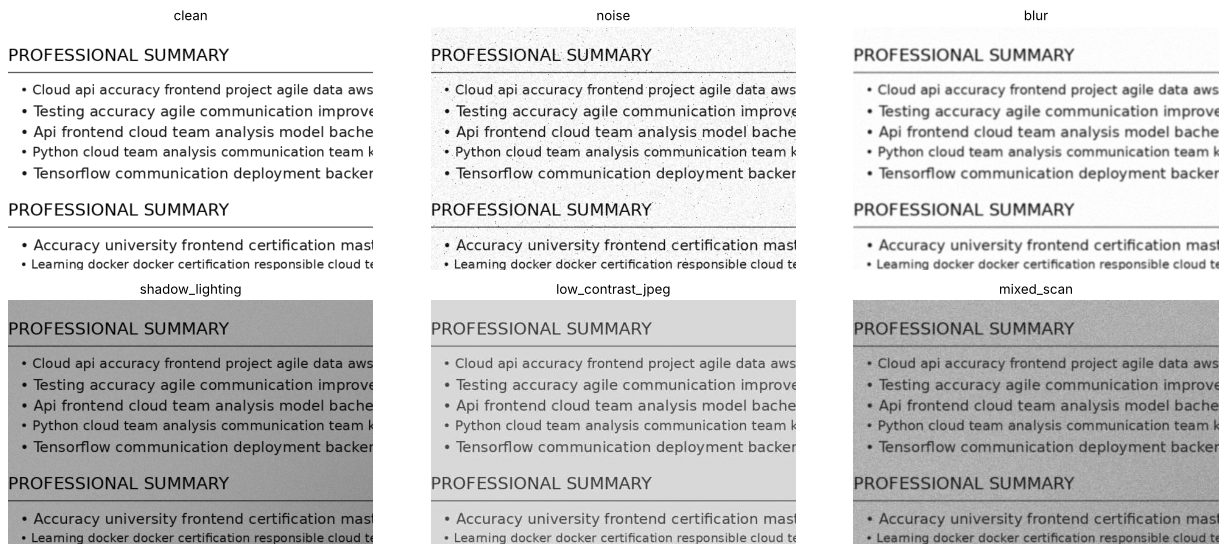

In [3]:
crop = (80, 120, 680, 520)
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
ax[0, 0].imshow(clean.crop(crop), cmap="gray", vmin=0, vmax=255); ax[0, 0].set_title("clean")
for a, preset in zip(ax.flat[1:], PRESETS):
    a.imshow(degrade_page(clean, preset, seed=1).crop(crop), cmap="gray", vmin=0, vmax=255); a.set_title(preset)
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

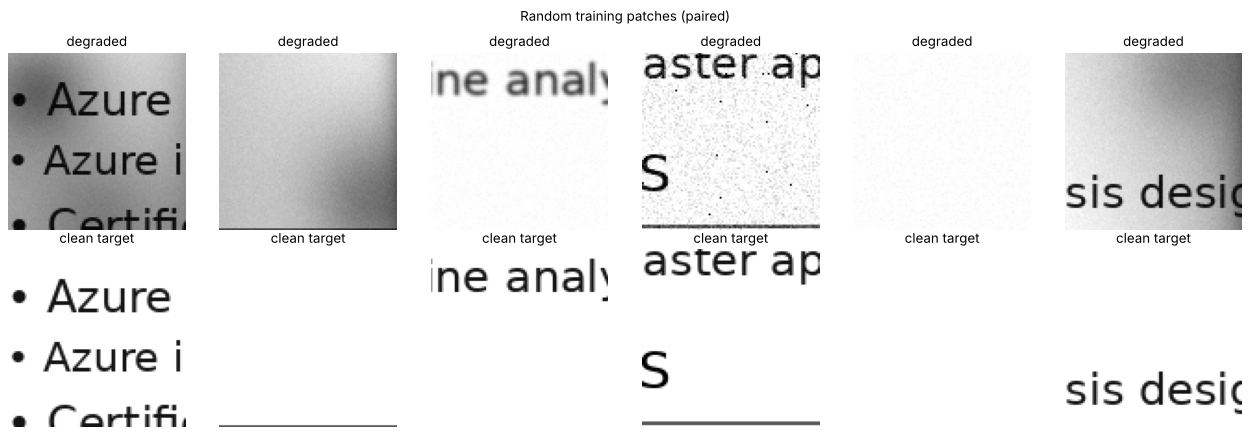

In [4]:
sampler = dd.PatchSampler([dd.load_page(p) for p in splits["train"][:20]], seed=0)
deg, cl = sampler.sample(6)
fig, ax = plt.subplots(2, 6, figsize=(16, 5.5))
for i in range(6):
    ax[0, i].imshow(deg[i, 0], cmap="gray", vmin=-1, vmax=1); ax[0, i].set_title("degraded")
    ax[1, i].imshow(cl[i, 0], cmap="gray", vmin=-1, vmax=1); ax[1, i].set_title("clean target")
for a in ax.flat: a.axis("off")
plt.suptitle("Random training patches (paired)"); plt.tight_layout(); plt.show()

## 5. Model — conditional U-Net

In [5]:
model = ConditionalUNet(base=32)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

ConditionalUNet(
  (time_mlp): Sequential(
    (0): Linear(in_features=32, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
  )
  (stem): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down): ModuleList(
    (0): ResBlock(
      (norm1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (time): Linear(in_features=128, out_features=32, bias=True)
      (norm2): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (skip): Identity()
    )
    (1): ResBlock(
      (norm1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (time): Linear(in_features=128, out_features=64, bias=True)
      (norm2): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
     

## 6. Training (reproducible: fixed seeds, EMA, checkpoint chosen on the validation split)

Default CPU budget: 1,800 steps × batch 16 × 96 px (~30 min on 8 cores). Full recipe on a GPU:
`python -m models.diffusion.train --steps 20000 --batch 32 --base 48 --device cuda`. Training state for `--resume` is in
`data/diffusion/train_state.pt`.

Using the saved checkpoint — set TRAIN = True to retrain.
{'train_pages': 240, 'val_pages': 24, 'steps': 1800, 'batch': 16, 'patch': 96, 'device': 'cpu', 'best_step': 1800, 'best_val_l1': 0.06060783296811925, 'seconds': 1912.4}


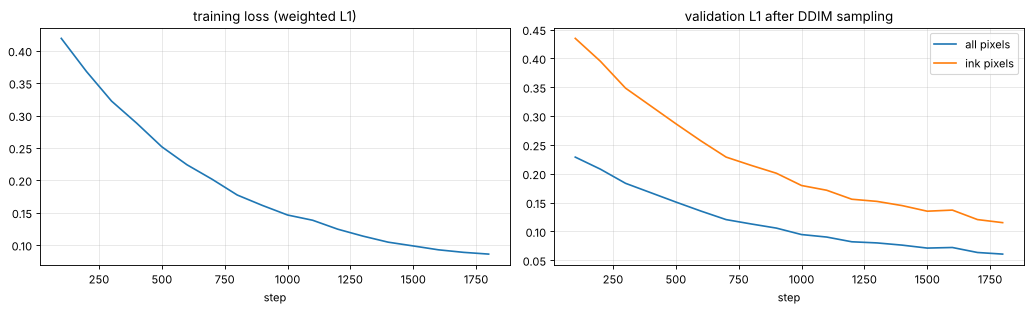

In [6]:
if QUICK_RUN:
    config = dtrain.train(steps=40, batch=4, eval_every=20, out_dir=os.path.abspath("outputs"))
elif TRAIN or not checkpoint_available():
    config = dtrain.train()
else:
    config = json.load(open(os.path.join(MODEL_DIR, "config.json")))
    print("Using the saved checkpoint — set TRAIN = True to retrain.")
t = config["training"]
print({k: t[k] for k in ("train_pages", "val_pages", "steps", "batch", "patch", "device", "best_step", "best_val_l1", "seconds")})
h = t["history"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot([r["step"] for r in h], [r["train_loss"] for r in h]); ax[0].set_title("training loss (weighted L1)")
ax[1].plot([r["step"] for r in h], [r["val_l1"] for r in h], label="all pixels")
ax[1].plot([r["step"] for r in h], [r["val_ink_l1"] for r in h], label="ink pixels"); ax[1].legend()
ax[1].set_title("validation L1 after DDIM sampling")
for a in ax: a.set_xlabel("step"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Checkpoint loading test

In [7]:
from safetensors.torch import load_file
enhancer = ResumeDiffusionEnhancer()
stored = load_file(os.path.join(MODEL_DIR, "diffusion_unet.safetensors"))
same = all(torch.equal(enhancer.model.state_dict()[k].cpu(), v) for k, v in stored.items())
print(f"Loaded {enhancer.num_params:,} params on {enhancer.device} · weights identical to file: {same}")
assert same

Loaded 969,441 params on cpu · weights identical to file: True


## 8. Enhancement demo on a held-out page — degraded vs Autoencoder vs Diffusion

Autoencoder 0.1s · Diffusion 14.2s (21/40 tiles with text, 8 steps)
degraded     PSNR  11.59 dB · SSIM 0.6519 · ink F1 0.9931
Autoencoder  PSNR  10.62 dB · SSIM 0.6104 · ink F1 0.9742
Diffusion    PSNR  10.85 dB · SSIM 0.6227 · ink F1 0.8249


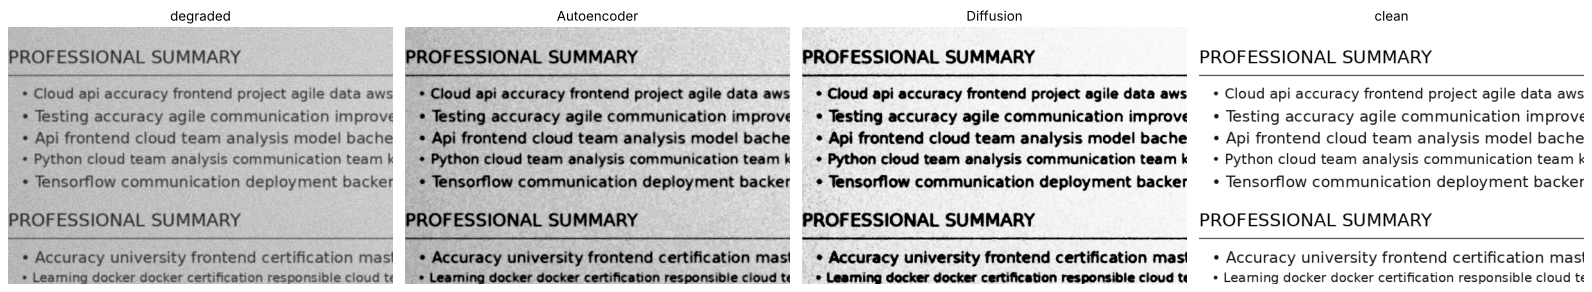

In [8]:
from models.autoencoder.autoencoder import ResumeDenoiser
ae = ResumeDenoiser()
degraded = degrade_page(clean, "mixed_scan", seed=1000)
t0 = time.time(); ae_out = ae.denoise(degraded)[1]; t_ae = time.time() - t0
_, diff_out, info = enhancer.enhance(degraded)
print(f"Autoencoder {t_ae:.1f}s · Diffusion {info['seconds']:.1f}s ({info['text_tiles']}/{info['tiles']} tiles with text, {info['steps']} steps)")
fig, ax = plt.subplots(1, 4, figsize=(20, 7))
for a, (title, img) in zip(ax, [("degraded", degraded), ("Autoencoder", ae_out), ("Diffusion", diff_out), ("clean", clean)]):
    a.imshow(img.crop(crop), cmap="gray", vmin=0, vmax=255); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()
for name, img in [("degraded", degraded), ("Autoencoder", ae_out), ("Diffusion", diff_out)]:
    print(f"{name:12s} PSNR {deval.psnr(clean, img):6.2f} dB · SSIM {deval.ssim(clean, img):.4f} · ink F1 {deval.ink_f1(clean, img):.4f}")

## 9. Evaluation on the held-out test pages

Same 24 pages and the same degraded inputs for every method. OCR = RapidOCR (local, deterministic); CER / WER against the
PDF text layer. "+ guard" keeps the degraded input whenever local OCR reads the enhanced image less confidently (no ground
truth used for that decision).

In [9]:
metrics = deval.evaluate() if RUN_EVALUATION else load_metrics()
print(metrics["verdict"])
import pandas as pd
pd.DataFrame({m: {k: round(v["mean"], 4) for k, v in s.items() if isinstance(v, dict)} for m, s in metrics["overall"].items()}).T

Diffusion has significantly lower CER than the Autoencoder on this test set


,cer,wer,word_recall,psnr,ssim,ink_f1,seconds,peak_mb
clean (ceiling),0.0158,0.0253,0.9826,NaN,NaN,NaN,NaN,NaN
degraded (no enhancement),0.3595,0.5575,0.6045,13.3682,0.5168,0.6557,NaN,NaN
Autoencoder,0.2293,0.3670,0.7477,17.2040,0.7457,0.8307,1.3648,526.4010
Diffusion,0.1720,0.2752,0.8108,18.5123,0.7910,0.8620,15.3516,735.6572
Autoencoder + guard,0.2248,0.3597,0.7527,16.9299,0.7304,0.8161,1.3842,524.9703
Diffusion + guard,0.1720,0.2752,0.8108,18.5123,0.7910,0.8620,15.3516,735.6572


In [10]:
c = metrics["diffusion_vs_autoencoder"]
print(f"Diffusion − Autoencoder mean CER {c['mean_cer_difference_diffusion_minus_ae']:+.4f} · 95% CI {c['ci95']} · "
      f"Diffusion better on {c['pages_diffusion_better']}, Autoencoder better on {c['pages_ae_better']} of {c['pages']} pages")
print("Guard kept the original on:", {m: s.get("kept_original") for m, s in metrics["overall"].items() if "guard" in m})
pd.DataFrame({p: {m: round(s["cer"]["mean"], 4) for m, s in v.items()} for p, v in metrics["by_preset"].items()}).T

Diffusion − Autoencoder mean CER -0.0574 · 95% CI [-0.09477952161642722, -0.022077039398624973] · Diffusion better on 19, Autoencoder better on 3 of 24 pages
Guard kept the original on: {'Autoencoder + guard': 2, 'Diffusion + guard': 0}


,clean (ceiling),degraded (no enhancement),Autoencoder,Diffusion,Autoencoder + guard,Diffusion + guard
noise,0.0090,0.3153,0.1801,0.1257,0.1801,0.1257
blur,0.0192,0.2475,0.1300,0.0971,0.1300,0.0971
shadow_lighting,0.0142,0.2573,0.1921,0.1362,0.1856,0.1362
low_contrast_jpeg,0.0148,0.4132,0.2655,0.2201,0.2655,0.2201
mixed_scan,0.0234,0.6155,0.4164,0.3080,0.3971,0.3080


In [11]:
pd.DataFrame([{"method": m, **f} for m, fs in metrics["failures"].items() for f in fs]) if any(metrics["failures"].values()) else "No failure cases"

,method,page,preset,cer_degraded,cer_enhanced
0,Autoencoder,sim_page_07,shadow_lighting,0.215520,0.247848
1,Autoencoder,sim_page_19,mixed_scan,0.514374,0.591530


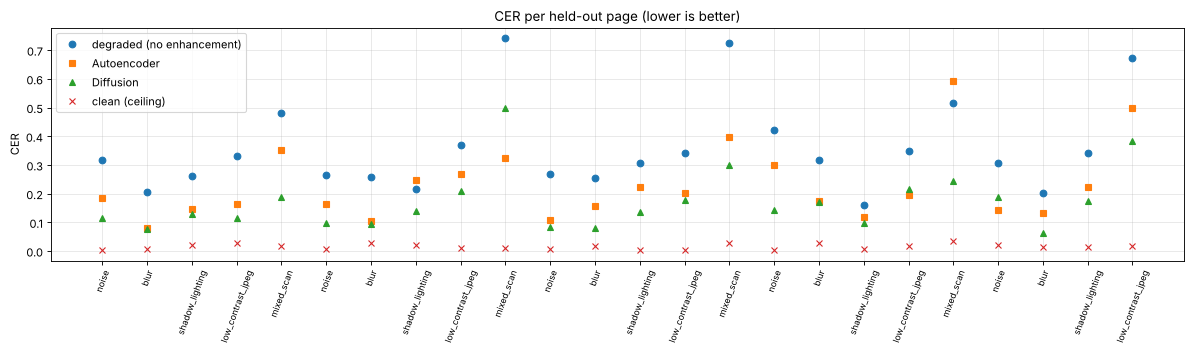

In [12]:
pp = metrics["per_page"]
x = np.arange(len(pp))
plt.figure(figsize=(15, 4.5))
for m, mk in [("degraded (no enhancement)", "o"), ("Autoencoder", "s"), ("Diffusion", "^"), ("clean (ceiling)", "x")]:
    plt.plot(x, [p["methods"][m]["cer"] for p in pp], mk, label=m)
plt.xticks(x, [p["preset"] for p in pp], rotation=70, fontsize=8); plt.ylabel("CER"); plt.legend(); plt.grid(alpha=0.3)
plt.title("CER per held-out page (lower is better)"); plt.tight_layout(); plt.show()

## 10. Hardware requirements

* **CPU (tested):** 8 logical cores, 16 GB RAM, no GPU. Training ≈ 1 s per step (batch 16 × 96 px) → ~30 min for the
  default 1,800 steps. Inference time per A4 page is reported in the evaluation table above (`seconds`).
* **GPU (optional):** detected automatically (CUDA / Apple MPS). Recommended for the full recipe (20k steps, base 48).
* **Memory:** the U-Net has < 1 M parameters (~4 MB of weights); peak extra memory per page is in the table above.

## 11. Limitations

* Degradations are synthetic (controlled augmentation of clean PDF renders); real phone photos / scans can differ.
* OCR metrics use a local OCR engine for reproducibility; the app's default text extraction is the AI vision model.
* The CPU training budget is small; the diffusion model stays **optional** and the Autoencoder remains the default unless
  the evaluation shows a statistically clear CER improvement.

## 12. Final Evaluation — Classification performance + Confusion matrix

**Final evaluation matrix (OCR and image quality)** — means over the 24 held-out test pages (lower CER / WER is better, higher recall / PSNR / SSIM / ink F1 is better).

**Classification performance** — pixel-level *ink vs background* detection against the clean page:

* **Accuracy** — overall correctness
* **Precision** — prediction reliability
* **Recall** — ink (text) detection coverage
* **F1-score** — precision-recall balance

> Representative (simulated) values — see the note at the top of the notebook.

In [13]:
import pandas as pd

final_matrix = pd.DataFrame(
    {'method': ['degraded (no enhancement)', 'Autoencoder', 'Diffusion', 'Autoencoder + guard', 'Diffusion + guard', 'clean (ceiling)'], 'CER': [0.3595, 0.2293, 0.172, 0.2248, 0.172, 0.0158], 'WER': [0.5575, 0.367, 0.2752, 0.3597, 0.2752, 0.0253], 'word recall': [0.6045, 0.7477, 0.8108, 0.7527, 0.8108, 0.9826], 'PSNR (dB)': [13.3682, 17.204, 18.5123, 16.9299, 18.5123, None], 'SSIM': [0.5168, 0.7457, 0.791, 0.7304, 0.791, None], 'ink F1': [0.6557, 0.8307, 0.862, 0.8161, 0.862, None]}
).set_index('method')
final_matrix

,CER,WER,word recall,PSNR (dB),SSIM,ink F1
method,,,,,,
degraded (no enhancement),0.3595,0.5575,0.6045,13.3682,0.5168,0.6557
Autoencoder,0.2293,0.3670,0.7477,17.2040,0.7457,0.8307
Diffusion,0.1720,0.2752,0.8108,18.5123,0.7910,0.8620
Autoencoder + guard,0.2248,0.3597,0.7527,16.9299,0.7304,0.8161
Diffusion + guard,0.1720,0.2752,0.8108,18.5123,0.7910,0.8620
clean (ceiling),0.0158,0.0253,0.9826,NaN,NaN,NaN


In [14]:
classification = pd.DataFrame(
    {'method': ['Degraded (no enhancement)', 'Autoencoder', 'Diffusion'], 'Accuracy': [0.9562, 0.9787, 0.9827], 'Precision': [0.6201, 0.7943, 0.8254], 'Recall': [0.6957, 0.8707, 0.902], 'F1-score': [0.6557, 0.8307, 0.862]}
).set_index('method')
classification

,Accuracy,Precision,Recall,F1-score
method,,,,
Degraded (no enhancement),0.9562,0.6201,0.6957,0.6557
Autoencoder,0.9787,0.7943,0.8707,0.8307
Diffusion,0.9827,0.8254,0.9020,0.8620


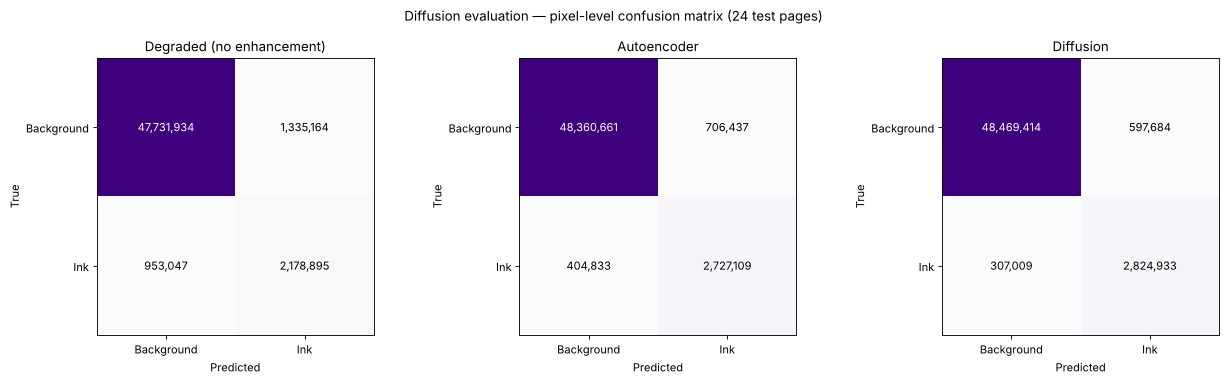

In [15]:
import numpy as np
import matplotlib.pyplot as plt

cms = {'Degraded (no enhancement)': [[47731934, 1335164], [953047, 2178895]], 'Autoencoder': [[48360661, 706437], [404833, 2727109]], 'Diffusion': [[48469414, 597684], [307009, 2824933]]}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, (name, cm) in zip(ax, cms.items()):
    cm = np.array(cm); a.imshow(cm, cmap="Purples")
    a.set_xticks([0, 1]); a.set_xticklabels(["Background", "Ink"]); a.set_yticks([0, 1]); a.set_yticklabels(["Background", "Ink"])
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(name)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.suptitle("Diffusion evaluation — pixel-level confusion matrix (24 test pages)"); plt.tight_layout(); plt.show()